# Контрольная работа: «Разработка сети объектов капитального строительства на территории страны»

**Объект исследования** — железнодорожная сеть России как сеть объектов капитального строительства:
- **узлы** — железнодорожные станции (здания, пути, платформы: объекты капстроительства с координатами, годом ввода и регионом);
- **рёбра** — перегоны (участки пути между соседними станциями; вес — длина, км).

**Источник данных** — открытая база знаний [Wikidata](https://www.wikidata.org): класс «железнодорожная станция» (Q55488),
свойства «соседняя станция» (P197), «координаты» (P625), «дата открытия» (P1619), «административная единица» (P131).
Данные выгружаются SPARQL-запросами и кэшируются в папке `data/`.

**Тип графа** (по методичке): инфраструктурная сеть (тип Г) — неориентированный взвешенный атрибутированный
пространственный граф. Перегон симметричен (поезда ходят в обе стороны), вес ребра — протяжённость.

**Содержание**
1. Данные: множества V и E, `nodes.csv`, `edges.csv`, построение графа, метрики, чек-лист пригодности для ML.
2. Алгоритмы контрольной работы (п. 1–10 задания): визуализация с привязкой к координатам, распределения степеней
   (линейная, полулогарифмическая, логарифмическая шкалы), модели Барабаши–Альберта, случайного роста, самоподобная сеть
   и ассортативность, модель Уоттса–Строгатца, сообщества Гирвана–Ньюмана и Лувена.
3. Кодирование признаков и объект `torch_geometric.data.Data`.
4. Базовая модель ML на графе: классификация узлов (федеральный округ станции) — GCN / GraphSAGE.
5. Выводы и ответы на контрольные вопросы.

Прогнозирование связей (аналитическая задача 6) и реферативный обзор (задача 7) — в ноутбуке
`Задачи_6_7_прогнозирование_связей_и_узлов.ipynb`.

## 1. Данные и построение графа

### 1.1 Сущности предметной области
| Множество | Сущность | Атрибуты |
|---|---|---|
| V (узлы) | железнодорожная станция | id, название, долгота, широта, год открытия, регион, население региона; **метка** — федеральный округ |
| E (рёбра) | перегон между соседними станциями | src, dst, длина (км, по геодезической прямой), тип |

Направленность: нет (отношение «соседняя станция» симметрично). Мультирёбер нет — дубликаты удаляются.

In [1]:
# ---------- Загрузка (с кэшем) и подготовка данных ----------
import os, io, time, json, math, random, warnings
from collections import Counter
import numpy as np, pandas as pd, requests, networkx as nx
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
UA = {"User-Agent": "GraphML-coursework/1.0 (educational)", "Accept": "text/csv"}

def sparql(query, path):
    """Запрос к Wikidata Query Service с кэшированием результата в CSV."""
    if not os.path.exists(path):
        r = requests.get("https://query.wikidata.org/sparql", params={"query": query}, headers=UA, timeout=300)
        r.raise_for_status()
        open(path, "w", encoding="utf-8").write(r.text)
    return pd.read_csv(path)

STATION = "wd:Q55488"   # железнодорожная станция
raw_nodes = sparql(f"""SELECT ?s ?sLabel ?coord ?open ?adm WHERE {{
  ?s wdt:P31 {STATION}; wdt:P17 wd:Q159; wdt:P625 ?coord . FILTER EXISTS {{ ?s wdt:P197 ?x }}
  OPTIONAL {{ ?s wdt:P1619 ?open }} OPTIONAL {{ ?s wdt:P131 ?adm }}
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "ru,en". }} }}""", "data/nodes_raw.csv")
raw_edges = sparql(f"""SELECT ?s ?a WHERE {{ ?s wdt:P31 {STATION}; wdt:P17 wd:Q159; wdt:P197 ?a . ?a wdt:P31 {STATION} . }}""",
                   "data/edges_raw.csv")
regions = sparql("""SELECT ?reg ?regLabel ?fd ?fdLabel ?pop WHERE { ?reg wdt:P31 wd:Q43263 .
  OPTIONAL { ?reg wdt:P361 ?fd . ?fd wdt:P31 wd:Q484215 } OPTIONAL { ?reg wdt:P1082 ?pop }
  SERVICE wikibase:label { bd:serviceParam wikibase:language "ru". } }""", "data/regions.csv")
regions = regions.sort_values("pop", ascending=False).drop_duplicates("reg")

# Административная единица станции (район/город) -> субъект РФ: поднимаемся по P131 пакетами
if not os.path.exists("data/adm_region.csv"):
    regset, parent, resolved = set(regions.reg), {}, {}
    adms = set(raw_nodes.adm.dropna())
    resolved.update({a: a for a in adms & regset})
    cur = {a: a for a in adms - regset}
    for _ in range(8):
        todo = sorted(set(cur.values()) - set(parent))
        for i in range(0, len(todo), 400):
            vals = " ".join("wd:" + x.rsplit("/", 1)[1] for x in todo[i:i + 400])
            r = requests.get("https://query.wikidata.org/sparql", headers=UA, timeout=300,
                             params={"query": f"SELECT ?a ?p WHERE {{ VALUES ?a {{ {vals} }} ?a wdt:P131 ?p }}"})
            for a, g in pd.read_csv(io.StringIO(r.text)).groupby("a"):
                parent[a] = list(g.p)
            time.sleep(1)
        nxt = {}
        for orig, c in cur.items():
            hit = [p for p in parent.get(c, []) if p in regset]
            if hit: resolved[orig] = hit[0]
            elif parent.get(c): nxt[orig] = parent[c][0]
        cur = nxt
        if not cur: break
    pd.DataFrame(list(resolved.items()), columns=["adm", "reg"]).to_csv("data/adm_region.csv", index=False)
adm_region = pd.read_csv("data/adm_region.csv")

# Узлы
xy = raw_nodes.coord.str.extract(r"Point\(([-\d.]+) ([-\d.]+)\)").astype(float)
raw_nodes["lon"], raw_nodes["lat"] = xy[0], xy[1]
raw_nodes["year"] = pd.to_datetime(raw_nodes.open, errors="coerce", utc=True).dt.year
nodes = (raw_nodes.groupby("s").agg(name=("sLabel", "first"), lon=("lon", "first"), lat=("lat", "first"),
                                     year=("year", "min"), adm=("adm", "first")).reset_index()
         .merge(adm_region, on="adm", how="left")
         .merge(regions[["reg", "regLabel", "fdLabel", "pop"]], on="reg", how="left"))
nodes["qid"] = nodes.s.str.rsplit("/", n=1).str[1]
nodes = nodes.rename(columns={"regLabel": "region", "fdLabel": "district", "pop": "region_pop"})
nodes["district"] = nodes["district"].str.replace(" федеральный округ", "", regex=False)

def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

# Рёбра: смежность станций (P197) -> неориентированный перегон, вес = длина по прямой, км
e = raw_edges[raw_edges.s != raw_edges.a].copy()
e[["u", "v"]] = np.sort(e[["s", "a"]].values, axis=1)
e = e.drop_duplicates(["u", "v"])
pos_ix = nodes.set_index("s")
e = e[e.u.isin(pos_ix.index) & e.v.isin(pos_ix.index)]
e["km"] = haversine(pos_ix.loc[e.u, "lon"].values, pos_ix.loc[e.u, "lat"].values,
                    pos_ix.loc[e.v, "lon"].values, pos_ix.loc[e.v, "lat"].values)
e = e[e.km <= 150]                       # единичные ошибки разметки ("соседи" за сотни км)

idx = {s: i for i, s in enumerate(nodes.s)}
nodes.insert(0, "id", range(len(nodes)))
edges = pd.DataFrame({"src": e.u.map(idx).values, "dst": e.v.map(idx).values, "km": e.km.round(3).values})
edges["type"] = "перегон"
nodes.drop(columns=["s", "adm", "reg"]).to_csv("nodes.csv", index=False)
edges.to_csv("edges.csv", index=False)

G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.id, name=r.name, lon=r.lon, lat=r.lat, year=r.year, region=r.region, district=r.district)
G.add_weighted_edges_from(edges[["src", "dst", "km"]].values, weight="km")
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
LCC = G.subgraph(max(nx.connected_components(G), key=len)).copy()
POS = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in G}
DISTRICTS = sorted(nodes.district.dropna().unique())
DCOLOR = dict(zip(DISTRICTS, plt.get_cmap("tab10").colors))

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def geo_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(55)))       # равнопромежуточная проекция с поправкой на широту
    ax.set_xlabel("долгота"); ax.set_ylabel("широта")

print(f"Станций (узлов): {G.number_of_nodes()}, перегонов (рёбер): {G.number_of_edges()}, "
      f"крупнейшая компонента: {LCC.number_of_nodes()} узлов")

Станций (узлов): 10625, перегонов (рёбер): 10834, крупнейшая компонента: 9950 узлов


In [2]:
print("nodes.csv:"); display(pd.read_csv("nodes.csv").head(8))
print("edges.csv:"); display(pd.read_csv("edges.csv").head(8))
print("Заполненность атрибутов узлов, %:")
print((nodes[["lon", "lat", "year", "region", "district"]].notna().mean() * 100).round(1).to_string())

nodes.csv:


,id,name,lon,lat,year,region,district,region_pop,qid
0,0,Магнитогорск-Пассажирский,58.981510,53.438320,1954.0,Челябинская область,Уральский,3385124.0,Q100152795
1,1,Кравцово,28.573871,60.773116,1885.0,Ленинградская область,Северо-Западный,2035762.0,Q100323807
2,2,Мержаново,39.095562,47.292056,1932.0,Ростовская область,Южный,4137335.0,Q100324331
3,3,Электродепо,39.755482,47.152804,NaN,Ростовская область,Южный,4137335.0,Q100522582
4,4,298 км,37.626930,55.171020,NaN,Московская область,Центральный,7708499.0,Q100777625
5,5,Повадино,37.745000,55.178890,NaN,Московская область,Центральный,7708499.0,Q100804878
6,6,309 км,37.792560,55.178740,NaN,Московская область,Центральный,7708499.0,Q100808115
7,7,312 км,37.841020,55.172460,NaN,Московская область,Центральный,7708499.0,Q100998091


edges.csv:


,src,dst,km,type
0,7983,10308,3.611,перегон
1,8210,10308,3.796,перегон
2,8213,10308,2.637,перегон
3,1955,10261,2.160,перегон
4,5680,10261,1.650,перегон
5,10262,10268,3.034,перегон
6,6466,10262,0.853,перегон
7,6855,10263,3.219,перегон


Заполненность атрибутов узлов, %:
lon         100.0
lat         100.0
year         65.2
region       98.4
district     98.4


### 1.2 Метрики графа

In [3]:
deg = dict(G.degree())
print(f"|V| = {G.number_of_nodes()}, |E| = {G.number_of_edges()}")
print(f"Плотность: {nx.density(G):.2e}")
print(f"Средняя степень: {2 * G.number_of_edges() / G.number_of_nodes():.3f}")
print(f"Средний коэффициент кластеризации: {nx.average_clustering(G):.4f}, транзитивность: {nx.transitivity(G):.4f}")
print(f"Компонент связности: {nx.number_connected_components(G)}; крупнейшая: {LCC.number_of_nodes()} узлов "
      f"({LCC.number_of_nodes() / G.number_of_nodes():.1%})")
print(f"Цикломатическое число LCC (|E|-|V|+1, число независимых циклов): {LCC.number_of_edges() - LCC.number_of_nodes() + 1}")
print(f"Суммарная длина перегонов: {sum(d['km'] for *_, d in G.edges(data=True)):,.0f} км (по прямой)")
print(f"Ассортативность по степени: {nx.degree_assortativity_coefficient(G):.3f}")
print("Распределение степеней:", dict(sorted(Counter(deg.values()).items())))

rng = np.random.default_rng(SEED)
src = rng.choice(list(LCC), 300, replace=False)
lens = [l for s in src for l in nx.single_source_shortest_path_length(LCC, s).values() if l > 0]
print(f"Средняя длина кратчайшего пути в LCC (по 300 случайным источникам): {np.mean(lens):.1f} перегонов")
print(f"Диаметр LCC (оценка снизу 2-sweep): {nx.approximation.diameter(LCC)} перегонов")

|V| = 10625, |E| = 10834
Плотность: 1.92e-04
Средняя степень: 2.039
Средний коэффициент кластеризации: 0.0057, транзитивность: 0.0146
Компонент связности: 39; крупнейшая: 9950 узлов (93.6%)
Цикломатическое число LCC (|E|-|V|+1, число независимых циклов): 244
Суммарная длина перегонов: 72,619 км (по прямой)
Ассортативность по степени: 0.144
Распределение степеней: {1: 325, 2: 9685, 3: 502, 4: 99, 5: 13, 6: 1}


Средняя длина кратчайшего пути в LCC (по 300 случайным источникам): 376.8 перегонов
Диаметр LCC (оценка снизу 2-sweep): 1399 перегонов


In [4]:
# Топ-5 станций по центральностям (посредничество - приближённо по 500 опорным узлам)
btw = nx.betweenness_centrality(LCC, k=500, seed=SEED)
top = pd.DataFrame({
    "станция": [G.nodes[n]["name"] for n in G],
    "регион": [G.nodes[n]["region"] for n in G],
    "степень": [deg[n] for n in G],
    "betweenness": [btw.get(n, 0) for n in G],
}, index=list(G))
display(top.sort_values("степень", ascending=False).head(5))
display(top.sort_values("betweenness", ascending=False).head(5).round(4))

,станция,регион,степень,betweenness
10244,Марьина Роща,Москва,6,0.036877
6985,Мга,Ленинградская область,5,0.086595
8626,Домодедово,Московская область,5,0.003604
8243,Агрыз,Татарстан,5,0.219817
8413,Брянск-Льговский,Брянская область,5,0.022686


,станция,регион,степень,betweenness
7726,Богданович,Свердловская область,4,0.3574
7930,Коменки,Свердловская область,2,0.3506
3801,Дубровный,Свердловская область,2,0.3506
3803,Пышминская,Свердловская область,2,0.3494
3804,Еланский,Свердловская область,2,0.3493


**Чек-лист пригодности для ML (п. 3.3 методички):** узлов ≥ 100 (≈10 тыс.) ✔; у всех вершин одинаковый вектор признаков
(формируется в разделе 3, пропуски года помечены флагом) ✔; числовые признаки нормализуются ✔; граф неориентированный —
обратные рёбра добавляются через `to_undirected` ✔; изолированные вершины удалены ✔; метки (федеральный округ) известны
для ~98% узлов, сплит 60/20/20 ✔; дисбаланс классов оценён ниже ✔.

## 2. Алгоритмы контрольной работы

### Алгоритм 1. Визуализация сети с привязкой узлов к координатам (NetworkX)
Позиции узлов `pos` — реальные долгота и широта станции, поэтому рисунок является схемой железных дорог страны.

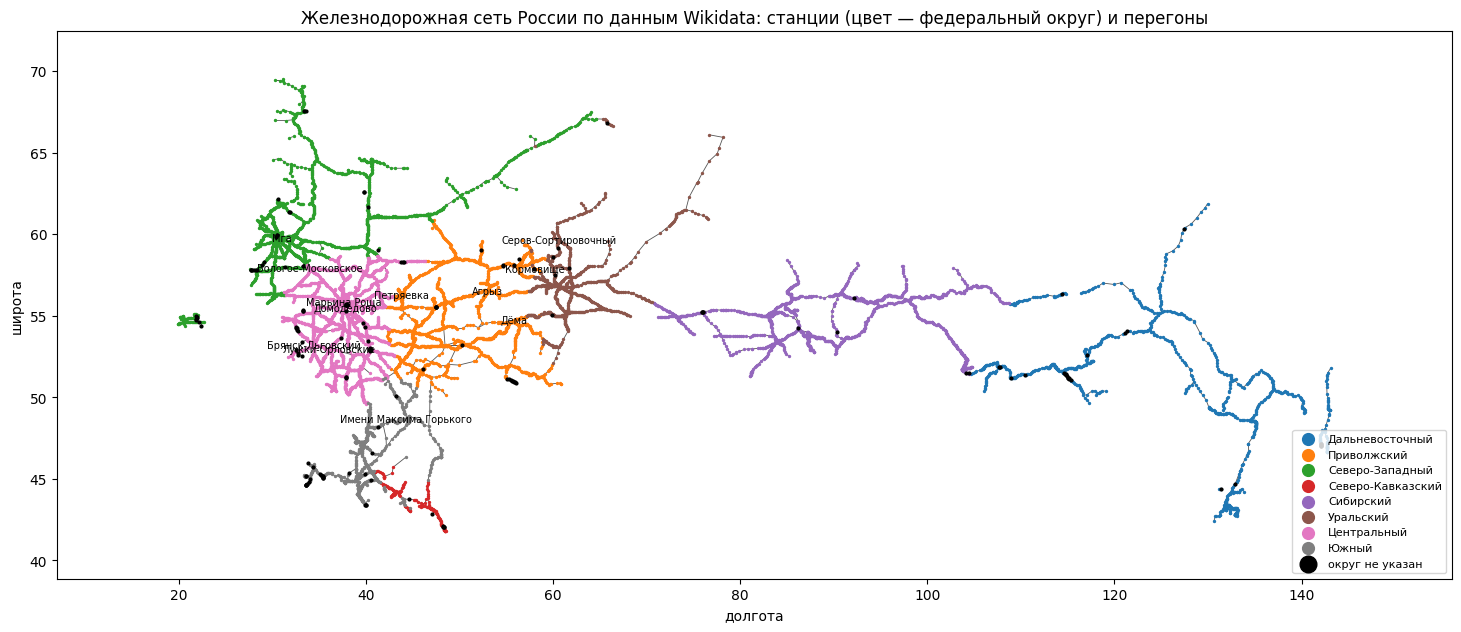

In [5]:
fig, ax = plt.subplots(figsize=(18, 9))
nx.draw_networkx_edges(G, POS, ax=ax, width=0.6, edge_color="#555555")
for d in DISTRICTS:
    nl = [n for n in G if G.nodes[n]["district"] == d]
    nx.draw_networkx_nodes(G, POS, nodelist=nl, ax=ax, node_size=2, node_color=[DCOLOR[d]], label=d)
nl = [n for n in G if not isinstance(G.nodes[n]["district"], str)]
nx.draw_networkx_nodes(G, POS, nodelist=nl, ax=ax, node_size=4, node_color="black", label="округ не указан")
hubs = sorted(G, key=deg.get, reverse=True)[:12]
nx.draw_networkx_labels(G, POS, labels={n: G.nodes[n]["name"] for n in hubs}, font_size=7, ax=ax)
geo_axes(ax); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax.legend(markerscale=6, fontsize=8, loc="lower right")
ax.set_title("Железнодорожная сеть России по данным Wikidata: станции (цвет — федеральный округ) и перегоны")
savefig("01_geo_network"); plt.show()

Узловой граф LCC: 818 узловых/тупиковых станций, 1029 линий; средняя длина линии 65 км


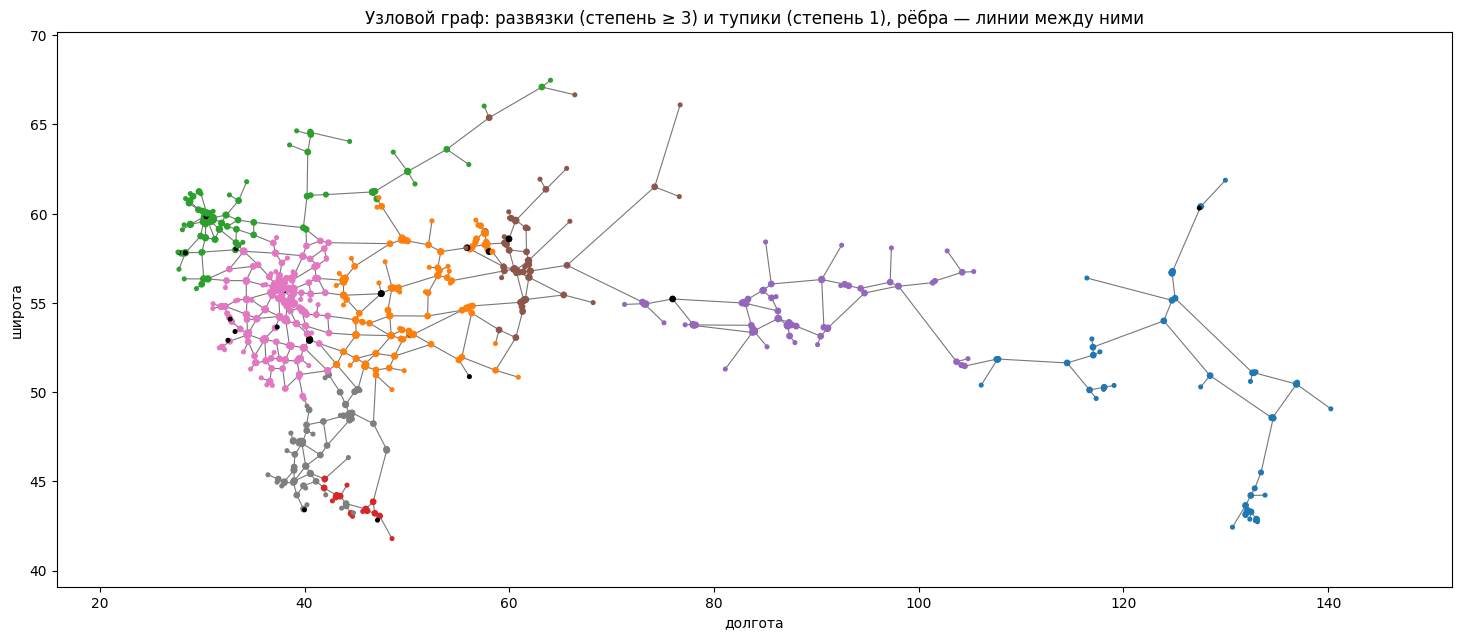

In [6]:
# Узловой граф: станции степени 2 стягиваются, ребро = линия между узловыми станциями (вес - суммарная длина)
def junction_graph(G):
    junc = {n for n in G if G.degree(n) != 2}
    J, seen = nx.Graph(), set()
    for u in junc:
        for nb in G.neighbors(u):
            if (u, nb) in seen:
                continue
            prev, cur, length, inner = u, nb, G[u][nb]["km"], 0
            while cur not in junc:
                nxt = [x for x in G.neighbors(cur) if x != prev][0]
                length += G[cur][nxt]["km"]; inner += 1
                prev, cur = cur, nxt
            seen.update({(u, nb), (cur, prev)})
            if u != cur and (not J.has_edge(u, cur) or J[u][cur]["km"] > length):
                J.add_edge(u, cur, km=length, stations=inner)
    for n in J:
        J.nodes[n].update(G.nodes[n])
    return J

J = junction_graph(LCC)
print(f"Узловой граф LCC: {J.number_of_nodes()} узловых/тупиковых станций, {J.number_of_edges()} линий; "
      f"средняя длина линии {np.mean([d['km'] for *_, d in J.edges(data=True)]):.0f} км")
fig, ax = plt.subplots(figsize=(18, 8))
JPOS = {n: POS[n] for n in J}
nx.draw_networkx_edges(J, JPOS, ax=ax, width=0.8, edge_color="#777777")
nx.draw_networkx_nodes(J, JPOS, ax=ax, node_size=[3 + 4 * J.degree(n) for n in J],
                       node_color=[DCOLOR.get(J.nodes[n]["district"], (0, 0, 0)) for n in J])
geo_axes(ax); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax.set_title("Узловой граф: развязки (степень ≥ 3) и тупики (степень 1), рёбра — линии между ними")
savefig("02_junction_graph"); plt.show()

### Алгоритмы 2–4. Плотность распределения степеней: обычная, полулогарифмическая и логарифмическая шкалы
$p(k) = N_k / N$ — доля узлов степени $k$. Строим для исходной сети станций и для узлового графа.

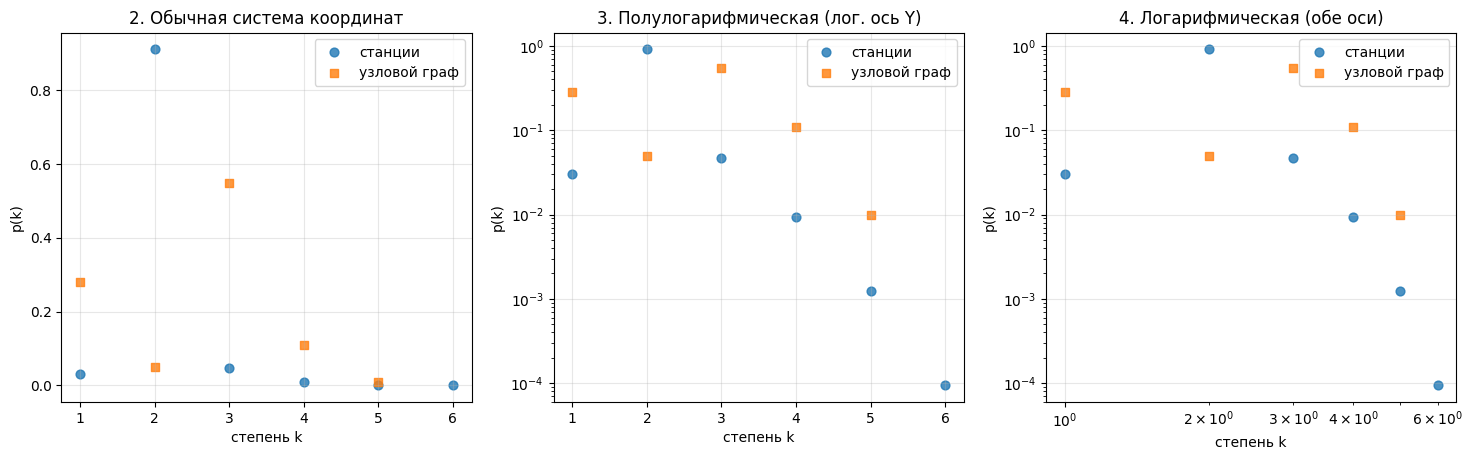

Узловой граф: хвост p(k) ~ exp(-2.01·k) — экспоненциальный, а не степенной (прямая на полулог. графике)


In [7]:
def degree_pmf(g):
    c = Counter(d for _, d in g.degree())
    k = np.array(sorted(c)); p = np.array([c[x] for x in k]) / g.number_of_nodes()
    return k, p

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for g, name, mk in [(G, "станции", "o"), (J, "узловой граф", "s")]:
    k, p = degree_pmf(g)
    for ax in axes:
        ax.scatter(k, p, marker=mk, s=40, label=name, alpha=0.8)
axes[1].set_yscale("log"); axes[2].set_xscale("log"); axes[2].set_yscale("log")
for ax, t in zip(axes, ["2. Обычная система координат", "3. Полулогарифмическая (лог. ось Y)", "4. Логарифмическая (обе оси)"]):
    ax.set_title(t); ax.set_xlabel("степень k"); ax.set_ylabel("p(k)"); ax.legend(); ax.grid(alpha=0.3)
savefig("03_degree_distributions"); plt.show()

kJ, pJ = degree_pmf(J)
m = kJ >= 3
slope = np.polyfit(kJ[m], np.log(pJ[m]), 1)[0]
print(f"Узловой граф: хвост p(k) ~ exp({slope:.2f}·k) — экспоненциальный, а не степенной (прямая на полулог. графике)")

**Вывод.** 91% станций имеют степень 2 (промежуточные станции на линии). Максимальная степень — 6, так что хвоста нет.
В полулогарифмической шкале убывание p(k) у узлового графа близко к прямой, то есть распределение **экспоненциальное**.
Железнодорожная сеть **не безмасштабная**: число путей, сходящихся в одной станции, ограничено физически
(место, стоимость путевого развития). Это типично для пространственных инфраструктурных сетей.

### Алгоритм 5. Модель Барабаши–Альберта и эмпирическое распределение степеней
Строим сеть BA с тем же числом узлов $N$, что и в LCC, и $m=1$ (средняя степень ≈ 2, как у ж/д сети).
Модель: рост + предпочтительное присоединение $\Pi(k_i) = k_i / \sum_j k_j$; теоретически $p(k) \sim k^{-3}$.

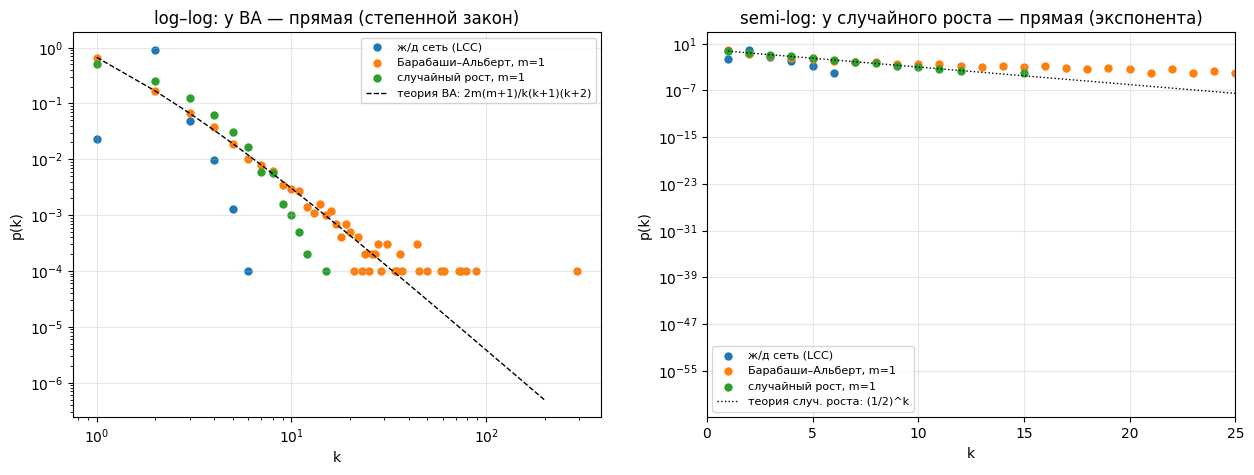

ж/д сеть        k_max=   6  <k>=2.05  <k²>=4.3
BA              k_max= 294  <k>=2.00  <k²>=22.1
случайный рост  k_max=  15  <k>=2.00  <k²>=6.0


In [8]:
N = LCC.number_of_nodes()
BA = nx.barabasi_albert_graph(N, 1, seed=SEED)

def random_growth(n, m=1, seed=SEED):
    """Случайный (равновероятный) рост: каждый новый узел присоединяется к m случайно выбранным существующим."""
    rng = np.random.default_rng(seed)
    g = nx.complete_graph(m + 1)
    for v in range(m + 1, n):
        for t in rng.choice(v, size=m, replace=False):
            g.add_edge(v, int(t))
    return g

RG = random_growth(N, 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for g, name in [(LCC, "ж/д сеть (LCC)"), (BA, "Барабаши–Альберт, m=1"), (RG, "случайный рост, m=1")]:
    k, p = degree_pmf(g)
    axes[0].scatter(k, p, s=25, label=name); axes[1].scatter(k, p, s=25, label=name)
kk = np.arange(1, 200)
axes[0].plot(kk, 4 / (kk * (kk + 1) * (kk + 2)), "k--", lw=1, label="теория BA: 2m(m+1)/k(k+1)(k+2)")
axes[1].plot(kk, 0.5 ** kk, "k:", lw=1, label="теория случ. роста: (1/2)^k")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("log–log: у BA — прямая (степенной закон)")
axes[1].set_yscale("log"); axes[1].set_xlim(0, 25); axes[1].set_title("semi-log: у случайного роста — прямая (экспонента)")
for ax in axes:
    ax.set_xlabel("k"); ax.set_ylabel("p(k)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
savefig("04_ba_random_growth"); plt.show()

for g, name in [(LCC, "ж/д сеть"), (BA, "BA"), (RG, "случайный рост")]:
    d = [x for _, x in g.degree()]
    print(f"{name:15s} k_max={max(d):4d}  <k>={np.mean(d):.2f}  <k²>={np.mean(np.square(d)):.1f}")

### Алгоритм 6. Сеть по случайному закону роста
Построена выше (`random_growth`): новый узел присоединяется к случайному узлу равновероятно, без предпочтения.
Эмпирическое распределение — геометрическое $p(k) = 2^{-k}$ (прямая в полулогарифмической шкале). У BA оно степенное с
хабами (k_max в сотни). Ж/д сеть не похожа ни на одну из моделей роста: её степени сосредоточены около 2 из-за
пространственных и технических ограничений.

### Алгоритм 7. Самоподобная сеть и анализ ассортативности
Строим детерминированный **(1,2)-цветок** (Rozenfeld, Havlin, ben-Avraham, 2007): на каждом поколении каждое ребро
заменяется на два параллельных пути длины 1 и 2. Сеть самоподобна (каждое поколение составлено из копий предыдущего)
и безмасштабна. Ассортативность анализируем диаграммами $k_{nn}(k)$ (средняя степень соседей узлов степени $k$)
и коэффициентом Ньюмана $r$.

(1,2)-цветок, 7 поколений: 1095 узлов, 2187 рёбер, k_max=128


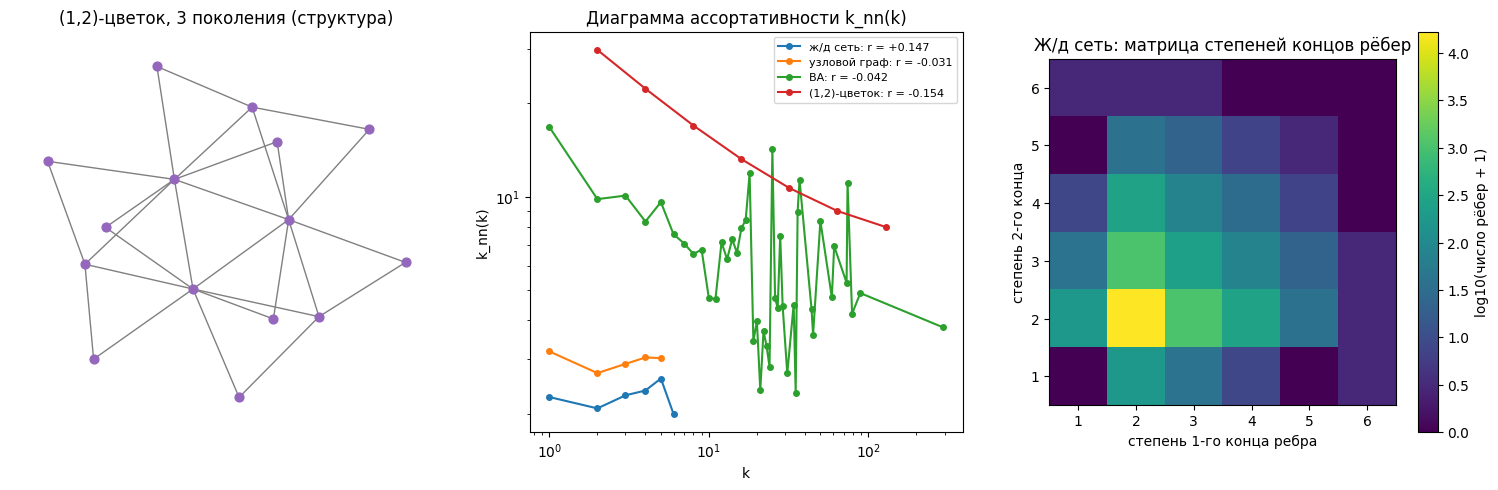

In [9]:
def uv_flower(generations, u=1, v=2):
    g = nx.Graph([(0, 1)])
    nxt = 2
    for _ in range(generations):
        h = nx.Graph()
        for a, b in g.edges():
            for L in (u, v):
                path = [a] + list(range(nxt, nxt + L - 1)) + [b]
                nxt += L - 1
                nx.add_path(h, path)
        g = h
    return g

FL = uv_flower(7)
print(f"(1,2)-цветок, 7 поколений: {FL.number_of_nodes()} узлов, {FL.number_of_edges()} рёбер, k_max={max(d for _, d in FL.degree())}")

def knn_curve(g):
    knn = nx.average_degree_connectivity(g)
    k = np.array(sorted(knn)); return k, np.array([knn[x] for x in k])

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
nx.draw_kamada_kawai(uv_flower(3), ax=axes[0], node_size=40, node_color="tab:purple", edge_color="gray")
axes[0].set_title("(1,2)-цветок, 3 поколения (структура)")
for g, name in [(LCC, "ж/д сеть"), (J, "узловой граф"), (BA, "BA"), (FL, "(1,2)-цветок")]:
    k, knn = knn_curve(g)
    axes[1].plot(k, knn, "o-", ms=4, label=f"{name}: r = {nx.degree_assortativity_coefficient(g):+.3f}")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("k"); axes[1].set_ylabel("k_nn(k)")
axes[1].set_title("Диаграмма ассортативности k_nn(k)"); axes[1].legend(fontsize=8)
ed = np.array([(LCC.degree(a), LCC.degree(b)) for a, b in LCC.edges()])
ed = np.vstack([ed, ed[:, ::-1]])
H2, xe, ye = np.histogram2d(ed[:, 0], ed[:, 1], bins=[np.arange(0.5, 7.5), np.arange(0.5, 7.5)])
im = axes[2].imshow(np.log10(H2 + 1), origin="lower", extent=[0.5, 6.5, 0.5, 6.5], cmap="viridis")
plt.colorbar(im, ax=axes[2], label="log10(число рёбер + 1)")
axes[2].set_xlabel("степень 1-го конца ребра"); axes[2].set_ylabel("степень 2-го конца")
axes[2].set_title("Ж/д сеть: матрица степеней концов рёбер")
savefig("05_self_similar_assortativity"); plt.show()

**Вывод.** Самоподобный цветок и BA — **дисассортативные** сети ($r<0$, $k_{nn}$ убывает: хабы соединены с узлами малой степени).
Ж/д сеть слабо ассортативна ($r>0$). Основная масса рёбер соединяет узлы степени 2 со степенью 2 (цепочки станций), а узловые станции
соединяются друг с другом линиями, то есть «хабов, к которым всё подключено» нет.

### Алгоритм 8. Модель Уоттса–Строгатца: кластеризация, диаметр и средняя длина пути
Кольцевая решётка $N=1000$, $k=4$ с вероятностью перестройки ребра $p$. Сравниваем с ж/д сетью.

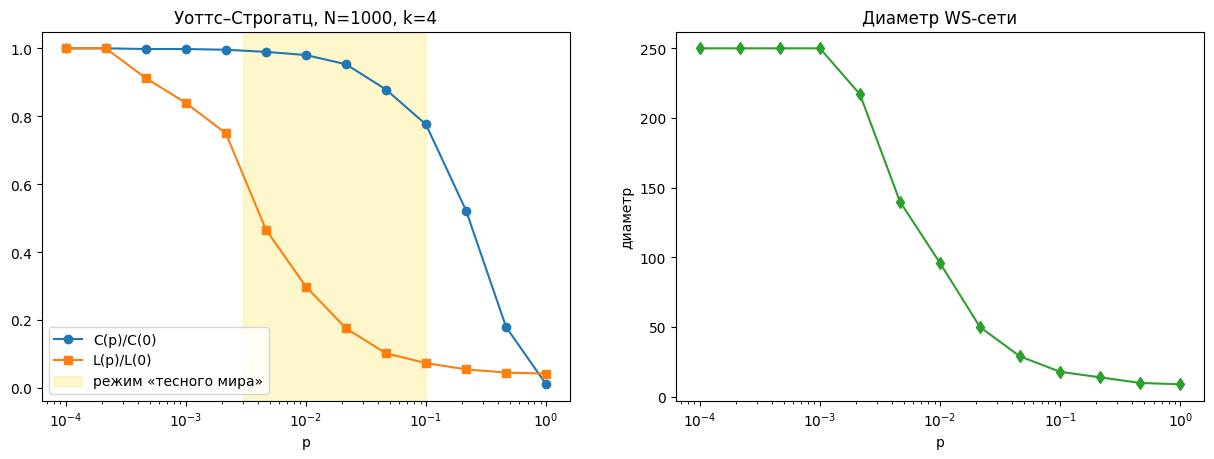

,p,C,L,D
0,0.0001,0.5000,125.3754,250
1,0.0002,0.5000,125.3754,250
2,0.0005,0.4990,114.3822,250
3,0.0010,0.4990,105.2498,250
4,0.0022,0.4979,94.0130,217
5,0.0046,0.4948,58.5160,140
6,0.0100,0.4901,37.4568,96
7,0.0215,0.4766,22.0836,50
8,0.0464,0.4394,12.8420,29
9,0.1000,0.3879,9.2265,18


Ж/д сеть: C = 0.0061, L ≈ 377; случайный граф с тем же <k>: L_rand ≈ ln N / ln<k> = 13


In [10]:
ps = np.logspace(-4, 0, 13)
res = []
for p in ps:
    ws = nx.connected_watts_strogatz_graph(1000, 4, p, seed=SEED)
    res.append((p, nx.average_clustering(ws), nx.average_shortest_path_length(ws), nx.diameter(ws)))
ws_df = pd.DataFrame(res, columns=["p", "C", "L", "D"])
C0, L0 = ws_df.C.iloc[0], ws_df.L.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].semilogx(ws_df.p, ws_df.C / C0, "o-", label="C(p)/C(0)")
axes[0].semilogx(ws_df.p, ws_df.L / L0, "s-", label="L(p)/L(0)")
axes[0].axvspan(3e-3, 1e-1, color="gold", alpha=0.2, label="режим «тесного мира»")
axes[0].set_xlabel("p"); axes[0].legend(); axes[0].set_title("Уоттс–Строгатц, N=1000, k=4")
axes[1].semilogx(ws_df.p, ws_df.D, "d-", color="tab:green"); axes[1].set_xlabel("p"); axes[1].set_ylabel("диаметр")
axes[1].set_title("Диаметр WS-сети")
savefig("06_watts_strogatz"); plt.show()
display(ws_df.round(4))

# Сопоставление: случайный граф с тем же N и <k> для ж/д сети
L_rail = np.mean(lens); C_rail = nx.average_clustering(LCC)
k_mean = 2 * LCC.number_of_edges() / LCC.number_of_nodes()
print(f"Ж/д сеть: C = {C_rail:.4f}, L ≈ {L_rail:.0f}; случайный граф с тем же <k>: L_rand ≈ ln N / ln<k> = "
      f"{np.log(LCC.number_of_nodes()) / np.log(k_mean):.0f}")

**Вывод.** В модели WS уже при $p \approx 0.01$ средний путь падает в разы, а кластеризация почти не меняется: это эффект **тесного мира**.
Ж/д сеть устроена противоположно: кластеризация почти нулевая (треугольников из перегонов почти нет), а средний путь — сотни
перегонов, на порядки больше, чем у случайного графа. Это «большой мир», решётчатая пространственная сеть. Для
проектирования отсюда следует, что даже немногие «перемычки» (новые линии-хорды) сильно сокращают пути, как случайные перестройки в WS.

### Алгоритм 9. Сообщества: алгоритм Гирвана–Ньюмана
Алгоритм последовательно удаляет ребро с максимальной посреднической центральностью (betweenness), сложность $O(m^2 n)$.
Поэтому применяем его к узловому графу одного округа — Северо-Западного — и выбираем разбиение с максимальной модулярностью.

Узловой граф СЗФО: 101 узлов, 120 рёбер
GN: лучший уровень — 10 сообществ, модулярность Q = 0.762 (0.1 с)


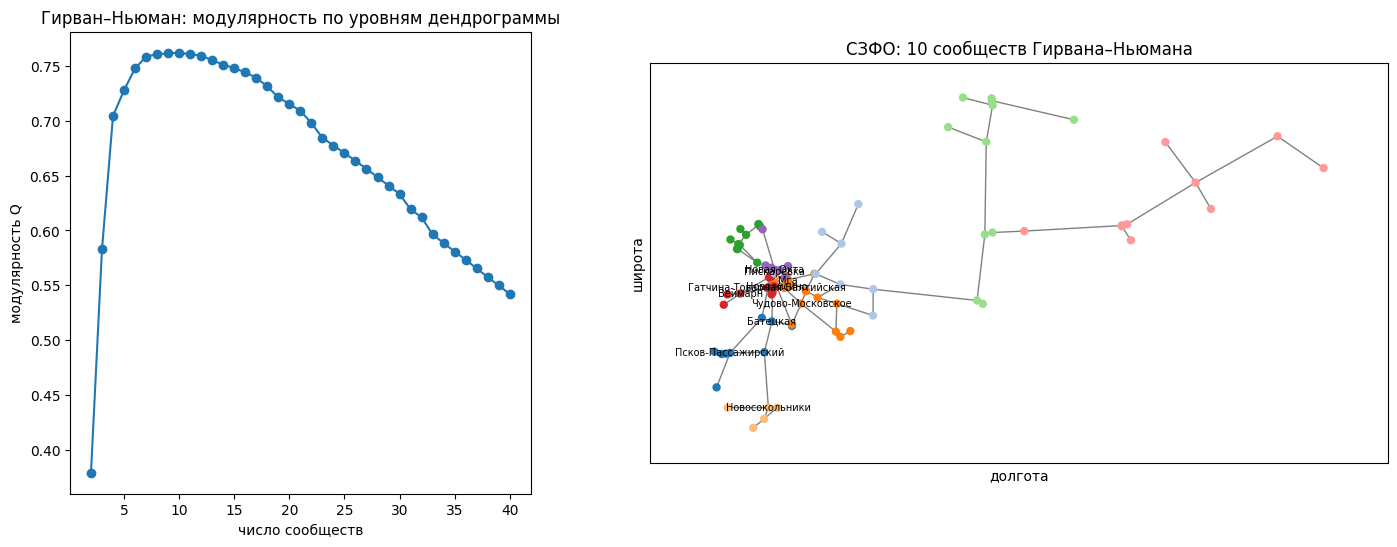

In [11]:
from networkx.algorithms import community as nxcom

NW = J.subgraph([n for n in J if J.nodes[n]["district"] == "Северо-Западный"])
NW = NW.subgraph(max(nx.connected_components(NW), key=len)).copy()
print(f"Узловой граф СЗФО: {NW.number_of_nodes()} узлов, {NW.number_of_edges()} рёбер")
t0 = time.time()
best_Q, best_part, history = -1, None, []
for level, part in enumerate(nxcom.girvan_newman(NW)):
    Q = nxcom.modularity(NW, part)
    history.append((len(part), Q))
    if Q > best_Q:
        best_Q, best_part = Q, part
    if len(part) >= 40:
        break
print(f"GN: лучший уровень — {len(best_part)} сообществ, модулярность Q = {best_Q:.3f} ({time.time() - t0:.1f} с)")

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot(*zip(*history), "o-"); axes[0].set_xlabel("число сообществ"); axes[0].set_ylabel("модулярность Q")
axes[0].set_title("Гирван–Ньюман: модулярность по уровням дендрограммы")
cmap = plt.get_cmap("tab20")
col = {n: cmap(i % 20) for i, c in enumerate(best_part) for n in c}
nx.draw_networkx_edges(NW, JPOS, ax=axes[1], edge_color="gray")
nx.draw_networkx_nodes(NW, JPOS, ax=axes[1], node_size=25, node_color=[col[n] for n in NW])
big = sorted(NW, key=NW.degree, reverse=True)[:10]
nx.draw_networkx_labels(NW, JPOS, labels={n: NW.nodes[n]["name"] for n in big}, font_size=7, ax=axes[1])
geo_axes(axes[1]); axes[1].set_title(f"СЗФО: {len(best_part)} сообществ Гирвана–Ньюмана")
savefig("07_girvan_newman"); plt.show()

### Алгоритм 10. Сообщества: алгоритм Лувена (максимизация модулярности)
Лувен работает почти линейно, поэтому применяем его ко всей сети (LCC). Сравниваем найденные сообщества
с административным делением на федеральные округа (NMI, ARI).

Лувен: 96 сообществ, модулярность Q = 0.971 (0.5 с); размеры топ-10: [203, 198, 179, 177, 165, 159, 150, 149, 149, 143]


Укрупнённое разбиение (resolution=0.02): 11 сообществ, Q = 0.892, NMI с федеральными округами = 0.713, ARI = 0.527


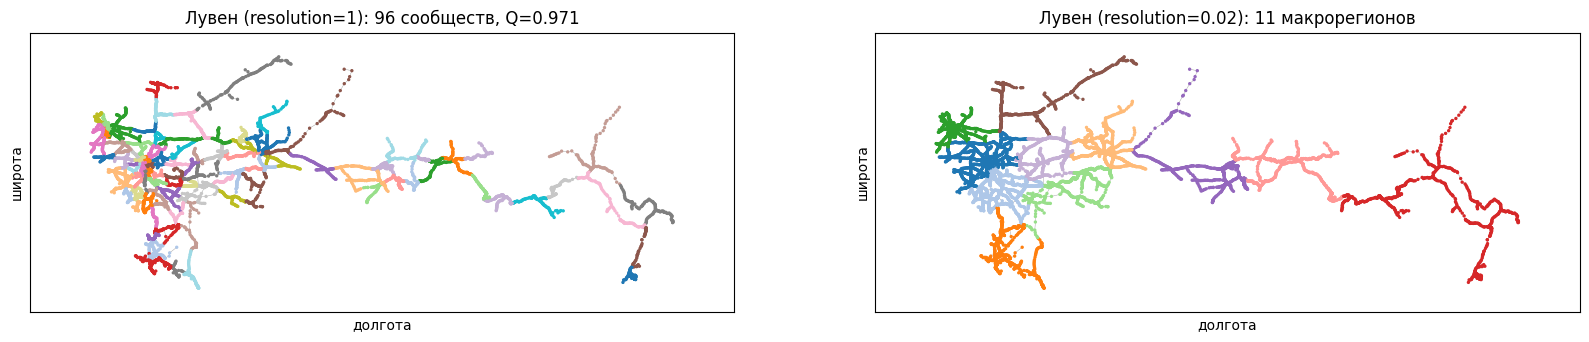

In [12]:
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

t0 = time.time()
louv = nxcom.louvain_communities(LCC, weight=None, seed=SEED, resolution=1.0)
louv = sorted(louv, key=len, reverse=True)
QL = nxcom.modularity(LCC, louv)
lab = {n: i for i, c in enumerate(louv) for n in c}
print(f"Лувен: {len(louv)} сообществ, модулярность Q = {QL:.3f} ({time.time() - t0:.1f} с); размеры топ-10: {[len(c) for c in louv[:10]]}")

# Укрупнение: уровень дендрограммы Лувена, сопоставимый по числу групп с федеральными округами
levels = list(nxcom.louvain_partitions(LCC, seed=SEED, resolution=0.02))
coarse = sorted(levels[-1], key=len, reverse=True)
clab = {n: i for i, c in enumerate(coarse) for n in c}
known = [n for n in LCC if isinstance(LCC.nodes[n]["district"], str)]
y_true = [LCC.nodes[n]["district"] for n in known]
print(f"Укрупнённое разбиение (resolution=0.02): {len(coarse)} сообществ, Q = {nxcom.modularity(LCC, coarse):.3f}, "
      f"NMI с федеральными округами = {normalized_mutual_info_score(y_true, [clab[n] for n in known]):.3f}, "
      f"ARI = {adjusted_rand_score(y_true, [clab[n] for n in known]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, labels, t in [(axes[0], lab, f"Лувен (resolution=1): {len(louv)} сообществ, Q={QL:.3f}"),
                      (axes[1], clab, f"Лувен (resolution=0.02): {len(coarse)} макрорегионов")]:
    nx.draw_networkx_edges(LCC, POS, ax=ax, width=0.3, edge_color="#999999")
    nx.draw_networkx_nodes(LCC, POS, ax=ax, node_size=2, node_color=[cmap(labels[n] % 20) for n in LCC])
    geo_axes(ax); ax.set_title(t)
savefig("08_louvain"); plt.show()

**Вывод по сообществам.** Модулярность пространственной сети очень высокая ($Q>0.9$): линии почти не пересекаются,
и сеть естественно делится на компактные участки, похожие на отделения дорог (96 сообществ,  = 0.97$).
Укрупнённое разбиение Лувена (11 макрорегионов) в значительной мере совпадает с федеральными округами (NMI ≈ 0.71, ARI ≈ 0.53),
то есть структура сети отражает территориальное устройство страны. Расхождения возникают там, где сеть «тянет» станции к
соседнему узлу через границу округа. Гирван–Ньюман на узловом графе СЗФО (101 узел) даёт максимум модулярности
 pprox 0.76$ при 10 сообществах: несколько групп Петербургского узла, псковское, новгородское и великолукское направления,
а также северо-восточные ветви (Архангельск / Котлас и Республика Коми).

## 3. Кодирование признаков для графовых нейросетей
| Признак | Тип | Обоснование |
|---|---|---|
| долгота, широта | числовой | положение объекта — главный фактор принадлежности к округу и соседства |
| год открытия (+ флаг пропуска) | числовой | эпоха строительства линии: соседние станции строились одновременно |
| степень узла | числовой | роль станции: промежуточная / узловая / тупиковая |
| средняя длина примыкающих перегонов, log | числовой | густота сети: пригород (короткие) или малонаселённые районы (длинные) |
| население субъекта, log | числовой | экономический масштаб региона |
| федеральный округ | категориальный → **метка** `y` (8 классов) | целевая переменная классификации узлов |

In [13]:
import torch
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected
from torch_geometric.nn import GCNConv, SAGEConv

torch.manual_seed(SEED)
nl = sorted(G)                                          # узлы графа (без изолированных)
remap = {n: i for i, n in enumerate(nl)}
df = nodes.set_index("id").loc[nl].copy()
df["degree"] = [G.degree(n) for n in nl]
df["mean_km"] = [np.log1p(np.mean([G[n][m]["km"] for m in G[n]])) for n in nl]
df["year_missing"] = df.year.isna().astype(float)
df["year"] = df.year.fillna(df.year.median())
df["log_pop"] = np.log(df.region_pop.fillna(df.region_pop.median()))
num_cols = ["lon", "lat", "year", "year_missing", "degree", "mean_km", "log_pop"]
X = StandardScaler().fit_transform(df[num_cols])

le = LabelEncoder().fit(DISTRICTS)
labeled = df.district.notna().values
y = np.full(len(nl), -1); y[labeled] = le.transform(df.district[labeled])

ei = torch.tensor([[remap[u], remap[v]] for u, v in G.edges()], dtype=torch.long).t()
data = Data(x=torch.tensor(X, dtype=torch.float), edge_index=to_undirected(ei), y=torch.tensor(y))
data.edge_attr = None

idx_l = np.where(labeled)[0]
tr, rest = train_test_split(idx_l, train_size=0.6, stratify=y[idx_l], random_state=SEED)
va, te = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=SEED)
for name, ids in [("train_mask", tr), ("val_mask", va), ("test_mask", te)]:
    m = torch.zeros(len(nl), dtype=torch.bool); m[ids] = True; data[name] = m
print(data)
print("Дисбаланс классов:", dict(zip(le.classes_, np.bincount(y[labeled]))))

Data(x=[10625, 7], edge_index=[2, 21668], y=[10625], train_mask=[10625], val_mask=[10625], test_mask=[10625])
Дисбаланс классов: {np.str_('Дальневосточный'): np.int64(906), np.str_('Приволжский'): np.int64(1881), np.str_('Северо-Западный'): np.int64(1714), np.str_('Северо-Кавказский'): np.int64(181), np.str_('Сибирский'): np.int64(1395), np.str_('Уральский'): np.int64(895), np.str_('Центральный'): np.int64(2678), np.str_('Южный'): np.int64(806)}


## 4. Базовая модель: классификация узлов (федеральный округ станции)

**Практический смысл.** У части станций в Wikidata не указан регион или его округ (в основном новые территории и
недавно добавленные записи). Модель восстанавливает атрибут по положению станции в сети. Так же решается задача
автоматической проверки и дополнения реестров объектов капстроительства.

Сравниваем: MLP (только признаки, без графа), GCN и GraphSAGE (2 слоя), Label Propagation (только граф).
Чтобы проверить, что даёт именно структура сети, обучаем модели также **без координат**.
Классы несбалансированы (СКФО ≈ 2%), поэтому используем веса классов.

In [14]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

class Net(torch.nn.Module):
    def __init__(self, kind, d_in, hid=64, n_cls=len(DISTRICTS)):
        super().__init__()
        self.kind = kind
        if kind == "GCN":   self.c1, self.c2 = GCNConv(d_in, hid), GCNConv(hid, n_cls)
        elif kind == "SAGE": self.c1, self.c2 = SAGEConv(d_in, hid), SAGEConv(hid, n_cls)
        else:                self.c1, self.c2 = torch.nn.Linear(d_in, hid), torch.nn.Linear(hid, n_cls)
    def forward(self, x, ei):
        f = (lambda l, h: l(h, ei)) if self.kind != "MLP" else (lambda l, h: l(h))
        h = F.dropout(F.relu(f(self.c1, x)), 0.3, self.training)
        return f(self.c2, h)

w = torch.tensor(len(idx_l) / (len(DISTRICTS) * np.bincount(y[labeled])), dtype=torch.float)

def fit(kind, x, epochs=400):
    torch.manual_seed(SEED)
    model = Net(kind, x.size(1)); opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    best, state = 0, None
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        out = model(x, data.edge_index)
        F.cross_entropy(out[data.train_mask], data.y[data.train_mask], weight=w).backward(); opt.step()
        model.eval(); pred = model(x, data.edge_index).argmax(1)
        acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()
        if acc > best: best, state = acc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()
    return model, model(x, data.edge_index).argmax(1).numpy()

def label_propagation(g_nodes, steps=200):
    """Итеративное распространение меток: каждый узел принимает распределение меток соседей; train-узлы закреплены."""
    A = nx.to_scipy_sparse_array(G, nodelist=nl, format="csr")
    Dinv = 1 / np.maximum(A.sum(1), 1)
    Y0 = np.zeros((len(nl), len(DISTRICTS))); Y0[tr, y[tr]] = 1
    Y = Y0.copy()
    for _ in range(steps):
        Y = (A @ Y) * Dinv[:, None]; Y[tr] = Y0[tr]
    return Y.argmax(1)

x_full = data.x
x_nocoord = data.x[:, [num_cols.index(c) for c in num_cols if c not in ("lon", "lat")]]
rows, preds = [], {}
for feats, x in [("с координатами", x_full), ("без координат", x_nocoord)]:
    for kind in ["MLP", "GCN", "SAGE"]:
        model, p = fit(kind, x)
        preds[(kind, feats)] = (model, p)
        rows.append({"модель": kind, "признаки": feats, "accuracy": accuracy_score(y[te], p[te]),
                     "macro-F1": f1_score(y[te], p[te], average="macro")})
p_lp = label_propagation(nl)
rows.append({"модель": "Label Propagation", "признаки": "только граф", "accuracy": accuracy_score(y[te], p_lp[te]),
             "macro-F1": f1_score(y[te], p_lp[te], average="macro")})
cls_res = pd.DataFrame(rows).round(4)
cls_res

,модель,признаки,accuracy,macro-F1
0,MLP,с координатами,0.9818,0.9825
1,GCN,с координатами,0.9823,0.9819
2,SAGE,с координатами,0.9885,0.9890
3,MLP,без координат,0.5339,0.4858
4,GCN,без координат,0.5789,0.5346
5,SAGE,без координат,0.6047,0.5693
6,Label Propagation,только граф,0.9933,0.9894


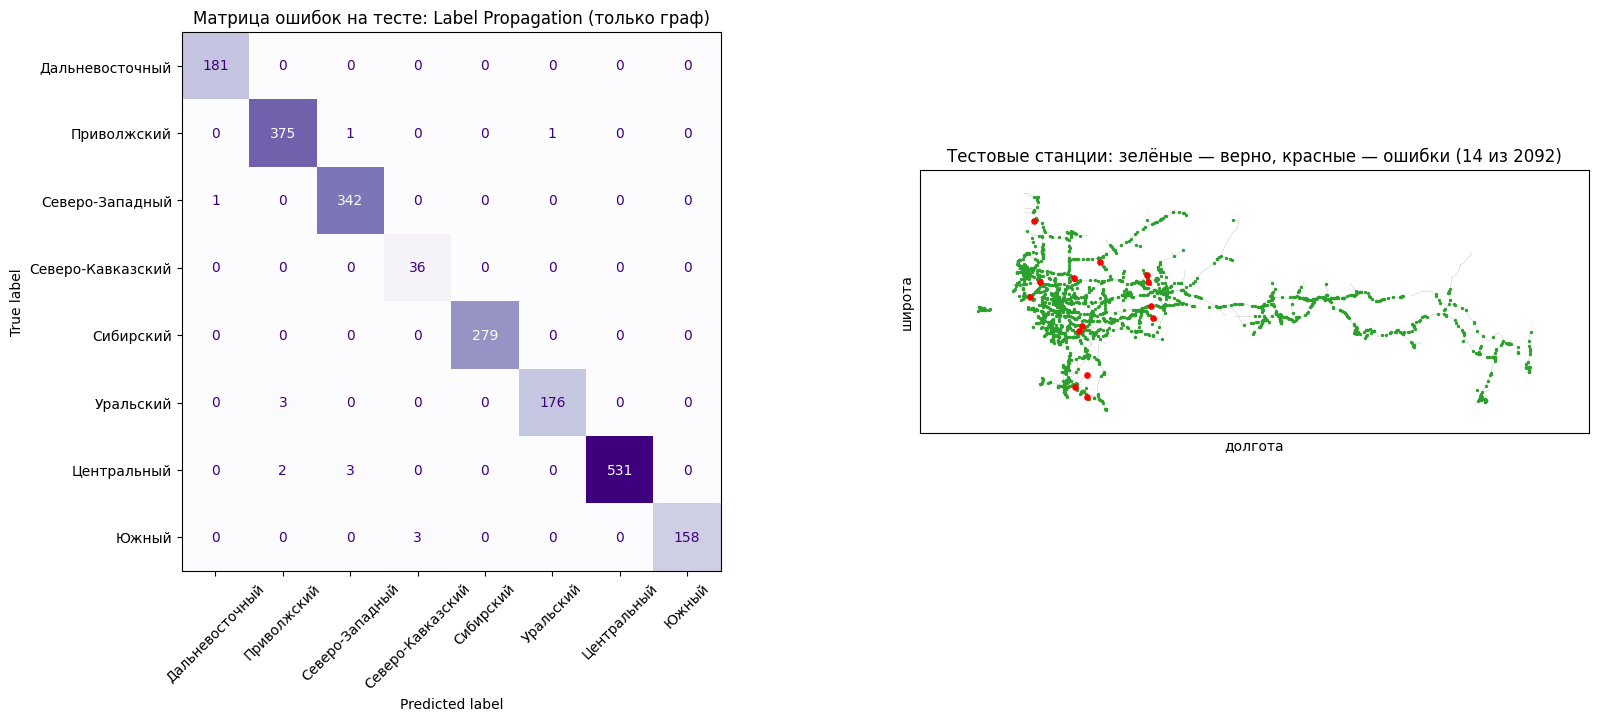

Станций без округа: 169. Предсказания модели:
предсказанный округ
Центральный          39
Дальневосточный      35
Южный                29
Северо-Западный      27
Приволжский          20
Сибирский             8
Уральский             6
Северо-Кавказский     5


,станция,регион (Wikidata),предсказанный округ
0,Пост ЭЦ,NaN,Приволжский
1,Канаш-Восточный,NaN,Приволжский
2,670 км,NaN,Приволжский
3,Старожилово,NaN,Центральный
4,Кача,NaN,Сибирский
5,Выя,NaN,Уральский
6,Александро-Невская,NaN,Центральный
7,Кочетовка III,NaN,Центральный
8,Новое Депо,NaN,Центральный
9,Кочетовка II,NaN,Центральный


In [15]:
best_row = cls_res.iloc[cls_res["macro-F1"].idxmax()]
model, p_best = preds.get((best_row["модель"], best_row["признаки"]), (None, p_lp))
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
ConfusionMatrixDisplay(confusion_matrix(y[te], p_best[te]), display_labels=le.classes_).plot(
    ax=axes[0], xticks_rotation=45, colorbar=False, cmap="Purples")
axes[0].set_title(f"Матрица ошибок на тесте: {best_row['модель']} ({best_row['признаки']})")
err = [nl[i] for i in te if p_best[i] != y[i]]
nx.draw_networkx_edges(G, POS, ax=axes[1], width=0.3, edge_color="#bbbbbb")
nx.draw_networkx_nodes(G, POS, nodelist=[nl[i] for i in te], ax=axes[1], node_size=2, node_color="tab:green")
nx.draw_networkx_nodes(G, POS, nodelist=err, ax=axes[1], node_size=14, node_color="red")
geo_axes(axes[1]); axes[1].set_title(f"Тестовые станции: зелёные — верно, красные — ошибки ({len(err)} из {len(te)})")
savefig("09_node_classification"); plt.show()

# Восстановление округа для станций, у которых он не указан
unl = np.where(~labeled)[0]
fill = pd.DataFrame({"станция": df.name.values[unl], "регион (Wikidata)": df.region.values[unl],
                     "предсказанный округ": le.inverse_transform(p_best[unl])})
print(f"Станций без округа: {len(unl)}. Предсказания модели:")
print(fill["предсказанный округ"].value_counts().to_string())
fill.head(10)

**Анализ ошибок.**
- Ошибки сосредоточены на границах округов: у станций на стыке есть соседи из обоих классов.
- С координатами все модели дают accuracy ≈ 0.98–0.99.
- Самый показательный результат — **Label Propagation**: только по связям сети, без каких-либо признаков, accuracy ≈ 0.99.
  Метка «растекается» вдоль линий на любое расстояние.
- GCN и GraphSAGE без координат дают лишь ≈ 0.58–0.60, хотя это всё равно лучше MLP (≈ 0.53). Причина в том, что двухслойная
  GNN видит только соседей на 2 перегона, а в цепочечной ж/д сети это несколько километров. Для таких сетей нужны глубокие
  модели или распространение меток (APPNP, label propagation): это важный практический вывод о выборе метода.
- 175 станций без округа — в основном записи Wikidata без административной привязки (служебные посты, остановочные
  пункты «… км»). Модель восстанавливает их округ по соседям; предсказания распределены по всем округам.

## 5. Выводы

1. Построена реальная сеть объектов капитального строительства страны — железнодорожная сеть России из Wikidata:
   ≈10,6 тыс. станций и ≈10,8 тыс. перегонов (≈73 тыс. км по прямой). Файлы `nodes.csv` и `edges.csv` сохранены. Граф пригоден для
   ML по чек-листу методички.
2. Сеть пространственная и почти древовидная: средняя степень 2.04, кластеризация ≈ 0.006, распределение степеней
   экспоненциальное (не степенное), средний путь — сотни перегонов («большой мир», не «тесный мир»).
3. Модели BA и случайного роста, самоподобный цветок и WS показывают, чем инфраструктурная сеть отличается от
   «социальных» моделей. Её структуру определяют география и стоимость строительства, а не предпочтительное присоединение.
4. Сообщества (Лувен, Гирван–Ньюман) имеют очень высокую модулярность и совпадают с территориальным делением.
   Для планирования это готовые зоны обслуживания и эксплуатационные участки.
5. Классификация узлов позволяет автоматически дополнять атрибуты реестра объектов (регион или округ), опираясь на связи.
   Для протяжённых цепочечных сетей распространение меток работает лучше неглубоких GNN без координат.

**Какие строительные решения поддерживает модель:** проверка и дополнение реестров объектов; выделение зон
обслуживания (сообщества); поиск «узких мест» с высокой посреднической центральностью, где нужны дублирующие линии;
оценка эффекта новых линий-хорд по аналогии с моделью WS. Прогноз недостающих и новых связей — в ноутбуке задач 6–7.

## Ответы на контрольные вопросы (кратко)
1. **Граф vs таблица.** Таблица хранит атрибуты станций, но теряет топологию: из неё нельзя ответить, как проехать от A до B,
   какие станции узловые и что изолируется при закрытии перегона. Граф хранит отношения явно.
2. **Матрица смежности vs список рёбер.** Матрица: проверка ребра за O(1), удобна для спектральных методов, но занимает O(V²) памяти
   (для нашей сети 10⁸ ячеек при 10⁴ рёбер). Список рёбер (`edge_index`) занимает O(E) и подходит для разреженных графов и PyG.
3. **Типы графов в строительстве.** Пространственный граф здания (помещения–двери); сетевой график (работы–зависимости, DAG);
   гетерогенный граф логистики (поставщик–материал–объект); инженерные и транспортные сети (как наша); динамический граф этапов.
4. **Ацикличность сетевого графика.** Цикл «A раньше B раньше A» невыполним. Проверка — `nx.is_directed_acyclic_graph(G)`
   или топологическая сортировка.
5. **Категориальные признаки** кодируются one-hot (немного категорий) или label encoding + обучаемый эмбеддинг (много категорий).
6. **Гетерогенный граф** содержит несколько типов узлов и рёбер (поставщик →поставляет→ материал →на→ объект),
   в PyG это `HeteroData`. Однородный граф имеет один тип.
7. **Граф из IFC.** `ifcopenshell`: узлы — `IfcSpace`, рёбра — общие `IfcDoor` / `IfcRelSpaceBoundary` между помещениями.
8. **Предсказание рёбер** оценивает вероятность связи между парой узлов. В проектировании оно находит пропущенные технологические
   зависимости и недостающие связи; у нас — пропущенные перегоны (см. задачу 6).
9. **Нормализация** выравнивает масштабы (год ~2000, степень ~2), стабилизирует градиенты и агрегацию по соседям.
10. **Дисбаланс классов:** веса классов в функции потерь (как здесь), стратифицированный сплит, oversampling, метрика macro-F1.